In [1]:
import pandas as pd

df = pd.read_csv("data/laptops_raw.csv")

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Shape: (1011, 11)

Columns:
['model', 'price', 'rating', 'processor', 'cores', 'ram', 'storage', 'display', 'graphics', 'os', 'warranty']


In [2]:
import sys
import pandas as pd
import numpy as np
import sklearn
import scipy

print("Python version :", sys.version)
print("Pandas version :", pd.__version__)
print("NumPy version  :", np.__version__)
print("Scikit-learn  :", sklearn.__version__)
print("SciPy version  :", scipy.__version__)

Python version : 3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]
Pandas version : 3.0.5
NumPy version  : 2.5.2
Scikit-learn  : 1.9.0
SciPy version  : 1.18.0


In [3]:
print("Dataset information:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

print("\nFirst 5 rows:")
display(df.head())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1011 entries, 0 to 1010
Data columns (total 11 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   model      1011 non-null   str    
 1   price      1011 non-null   str    
 2   rating     1010 non-null   float64
 3   processor  1003 non-null   str    
 4   cores      988 non-null    str    
 5   ram        1008 non-null   str    
 6   storage    1007 non-null   str    
 7   display    1011 non-null   str    
 8   graphics   1001 non-null   str    
 9   os         1008 non-null   str    
 10  warranty   1007 non-null   str    
dtypes: float64(1), str(10)
memory usage: 87.0 KB
None

Missing values:
model         0
price         0
rating        1
processor     8
cores        23
ram           3
storage       4
display       0
graphics     10
os            3
warranty      4
dtype: int64

First 5 rows:


,model,price,rating,processor,cores,ram,storage,display,graphics,os,warranty
0,Lenovo Legion Pro 5 16IAX10 83F3007CIN Gaming ...,"₹1,89,990",84.0,Intel Core Ultra 7 255HX,"20 Cores (8P + 12E), 20 Threads",32 GB DDR5 RAM,1 TB SSD,"16 inches, 2560 x 1600 pixels",8 GB NVIDIA® GeForce RTX 5060,Windows 11 OS,1 Year Warranty
1,Lenovo IdeaPad Slim 3 83K100HSIN Laptop (13th ...,"₹62,350",54.0,13th Gen Intel Core i5 13420H,"Octa Core (4P + 4E), 12 Threads",16 GB LPDDR5 RAM,1 TB SSD,"15.6 inches, 1920 x 1080 pixels",Integrated Intel UHD Graphics,Windows 11 OS,1 Year Warranty
2,Asus Vivobook Go 15 E1504FA-BQ2343WS Laptop (A...,"₹34,990",51.0,7th Gen AMD Ryzen 3 7320U,"Quad Core, 8 Threads",16 GB LPDDR5 RAM,512 GB SSD,"15.6 inches, 1920 x 1080 pixels",AMD Radeon AMD,Windows 11 OS,1 Year Warranty
3,Lenovo V14 G3 82TS00JGUS Laptop (12th Gen Core...,"₹56,990",48.0,12th Gen Intel Core i7 1255U,"10 Cores (2P + 8E), 12 Threads",16 GB RAM,512 GB SSD,"14 inches, 1920 x 1080 pixels",Integrated Intel Iris Xe Graphics,Windows 11 OS,1 Year Warranty
4,Dell DC 14250 ODC1425000401RINS1 Laptop (Intel...,"₹69,990",52.0,Intel Core 5 120U,"10 Cores (2P + 8E), 12 Threads",16 GB DDR5 RAM,512 GB SSD,"14 inches, 1920 x 1080 pixels",Intel UHD Graphics,Windows 11 OS,1 Year Warranty


In [4]:
print("Price examples:")
print(df["price"].head(10).tolist())

print("\nUnique values in rating:")
print(df["rating"].dropna().unique()[:20])

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Price examples:
['₹1,89,990', '₹62,350', '₹34,990', '₹56,990', '₹69,990', '₹37,800', '₹29,990', '₹33,990', '₹82,999', '₹79,990']

Unique values in rating:
[84. 54. 51. 48. 52. 50. 44. 69. 55. 33. 42. 70. 45. 57. 59. 92. 91. 78.
 71. 75.]

Missing values:
model         0
price         0
rating        1
processor     8
cores        23
ram           3
storage       4
display       0
graphics     10
os            3
warranty      4
dtype: int64

Duplicate rows: 2


In [5]:
df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after removing duplicates:", df.shape)
print("Duplicate rows remaining:", df.duplicated().sum())

Dataset shape after removing duplicates: (1009, 11)
Duplicate rows remaining: 0


In [6]:
df["price"] = (
    df["price"]
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
    .astype(float)
)

print(df["price"].dtype)
print(df["price"].head(10))

float64
0    189990.0
1     62350.0
2     34990.0
3     56990.0
4     69990.0
5     37800.0
6     29990.0
7     33990.0
8     82999.0
9     79990.0
Name: price, dtype: float64


In [7]:
print("Minimum price :", df["price"].min())
print("Maximum price :", df["price"].max())
print("Average price :", df["price"].mean())
print("Median price  :", df["price"].median())

Minimum price : 10999.0
Maximum price : 605990.0
Average price : 86939.86422200198
Median price  : 67499.0


In [8]:
print("\nPrice statistics:")
print(df["price"].describe())


Price statistics:
count      1009.000000
mean      86939.864222
std       68382.922528
min       10999.000000
25%       44990.000000
50%       67499.000000
75%       98907.000000
max      605990.000000
Name: price, dtype: float64


In [9]:
columns_to_inspect = [
    "processor",
    "cores",
    "ram",
    "storage",
    "display",
    "graphics",
    "os",
    "warranty"
]

for column_name in columns_to_inspect:
    print(f"\n{'=' * 60}")
    print(f"{column_name.upper()}")
    print(df[column_name].dropna().head(10).tolist())


PROCESSOR
['Intel Core Ultra 7 255HX', '13th Gen Intel Core i5 13420H', '7th Gen AMD Ryzen 3 7320U', '12th Gen Intel Core i7 1255U', 'Intel Core 5 120U', 'Intel Core i3 100U', '7th Gen AMD Ryzen 3 7320U', '7th Gen AMD Ryzen 5 7430U', '14th Gen Intel Core i5 14450HX', '13th Gen Intel Core i5 13420H']

CORES
['20 Cores (8P + 12E), 20 Threads', 'Octa Core (4P + 4E), 12 Threads', 'Quad Core, 8 Threads', '10 Cores (2P + 8E), 12 Threads', '10 Cores (2P + 8E), 12 Threads', 'Hexa Core (2P + 4E), 8 Threads', 'Quad Core, 8 Threads', 'Hexa Core, 12 Threads', '10 Cores (6P + 4E), 16 Threads', 'Octa Core (4P + 4E), 12 Threads']

RAM
['32 GB DDR5 RAM', '16 GB LPDDR5 RAM', '16 GB LPDDR5 RAM', '16 GB  RAM', '16 GB DDR5 RAM', '16 GB DDR5 RAM', '8 GB LPDDR5 RAM', '8 GB DDR4 RAM', '24 GB DDR5 RAM', '16 GB DDR4 RAM']

STORAGE
['1 TB SSD', '1 TB SSD', '512 GB SSD', '512 GB SSD', '512 GB SSD', '512 GB SSD', '512 GB SSD', '512 GB SSD', '512 GB SSD', '512 GB SSD']

DISPLAY
['16 inches, 2560 x 1600 pixels', '

In [10]:
print("Unique values in each column:\n")

for column_name in df.columns:
    print(
        f"{column_name:12} : "
        f"{df[column_name].nunique(dropna=True)} unique values"
    )

Unique values in each column:

model        : 1009 unique values
price        : 567 unique values
rating       : 67 unique values
processor    : 158 unique values
cores        : 48 unique values
ram          : 49 unique values
storage      : 11 unique values
display      : 77 unique values
graphics     : 121 unique values
os           : 11 unique values
warranty     : 3 unique values


In [11]:
print("\nMissing values after duplicate removal:\n")
print(df.isnull().sum())


Missing values after duplicate removal:

model         0
price         0
rating        1
processor     8
cores        23
ram           3
storage       4
display       0
graphics     10
os            3
warranty      4
dtype: int64


In [12]:
laptop_data = df.copy()

print("Working dataset shape:", laptop_data.shape)
print("Original dataset shape:", df.shape)

Working dataset shape: (1009, 11)
Original dataset shape: (1009, 11)


In [13]:
X = laptop_data.drop(columns=["price"])
y = laptop_data["price"]

print("Feature shape :", X.shape)
print("Target shape  :", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

Feature shape : (1009, 10)
Target shape  : (1009,)

Feature columns:
['model', 'rating', 'processor', 'cores', 'ram', 'storage', 'display', 'graphics', 'os', 'warranty']


In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features :", X_train.shape)
print("Testing features  :", X_test.shape)
print("Training target   :", y_train.shape)
print("Testing target    :", y_test.shape)

Training features : (807, 10)
Testing features  : (202, 10)
Training target   : (807,)
Testing target    : (202,)


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numeric_features = [
    "rating"
]

categorical_features = [
    "model",
    "processor",
    "cores",
    "ram",
    "storage",
    "display",
    "graphics",
    "os",
    "warranty"
]

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=2
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_preprocessor, numeric_features),
    ("categorical", categorical_preprocessor, categorical_features)
])

print("Preprocessor created successfully.")

Preprocessor created successfully.


In [16]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Original training shape :", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nOriginal testing shape  :", X_test.shape)
print("Processed testing shape :", X_test_processed.shape)

print("\nProcessed data type:", type(X_train_processed))

Original training shape : (807, 10)
Processed training shape: (807, 311)

Original testing shape  : (202, 10)
Processed testing shape : (202, 311)

Processed data type: <class 'scipy.sparse._csr.csr_matrix'>


In [17]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

linear_model = LinearRegression()

ridge_model = Ridge(alpha=10)

random_forest_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=30,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

gradient_boosting_model = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

print("All models created successfully.")

All models created successfully.


## First we train Linear Regression Model

In [18]:
linear_model.fit(
    X_train_processed,
    y_train
)

linear_predictions = linear_model.predict(
    X_test_processed
)

print("Linear Regression trained successfully.")
print("Number of predictions:", len(linear_predictions))

Linear Regression trained successfully.
Number of predictions: 202


## Second we train Ridge Regression Model

In [19]:
ridge_model.fit(
    X_train_processed,
    y_train
)

ridge_predictions = ridge_model.predict(
    X_test_processed
)

print("Ridge Regression trained successfully.")
print("Number of predictions:", len(ridge_predictions))

Ridge Regression trained successfully.
Number of predictions: 202


## Random Forest Model

In [20]:
random_forest_model.fit(
    X_train_processed,
    y_train
)

random_forest_predictions = random_forest_model.predict(
    X_test_processed
)

print("Random Forest trained successfully.")
print("Number of predictions:", len(random_forest_predictions))

Random Forest trained successfully.
Number of predictions: 202


## Gradiant Boosting Model 

In [21]:
gradient_boosting_model.fit(
    X_train_processed,
    y_train
)

gradient_boosting_predictions = gradient_boosting_model.predict(
    X_test_processed
)

print("Gradient Boosting trained successfully.")
print("Number of predictions:", len(gradient_boosting_predictions))

Gradient Boosting trained successfully.
Number of predictions: 202


## Evaluating all 4 Models 

In [22]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

model_predictions = {
    "Linear Regression": linear_predictions,
    "Ridge Regression": ridge_predictions,
    "Random Forest": random_forest_predictions,
    "Gradient Boosting": gradient_boosting_predictions
}

model_results = []

for model_name, predictions in model_predictions.items():

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    model_results.append({
        "Model": model_name,
        "MAE (₹)": round(mae, 2),
        "RMSE (₹)": round(rmse, 2),
        "R²": round(r2, 4)
    })

model_comparison = pd.DataFrame(model_results)

model_comparison = model_comparison.sort_values(
    by="R²",
    ascending=False
).reset_index(drop=True)

model_comparison

,Model,MAE (₹),RMSE (₹),R²
0,Linear Regression,11613.12,16827.93,0.9180
1,Random Forest,10633.04,19457.37,0.8904
2,Gradient Boosting,12432.50,20122.92,0.8828
3,Ridge Regression,14721.40,20983.61,0.8726


In [23]:
from sklearn.model_selection import cross_validate

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=10),
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        max_depth=30,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

cv_results = []

for model_name, model in models.items():

    model_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    scores = cross_validate(
        model_pipeline,
        X_train,
        y_train,
        cv=5,
        scoring={
            "r2": "r2",
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error"
        },
        n_jobs=-1
    )

    cv_results.append({
        "Model": model_name,
        "CV R² Mean": scores["test_r2"].mean(),
        "CV R² Std": scores["test_r2"].std(),
        "CV MAE (₹)": -scores["test_mae"].mean(),
        "CV RMSE (₹)": -scores["test_rmse"].mean()
    })

cv_comparison = pd.DataFrame(cv_results)

cv_comparison = cv_comparison.sort_values(
    "CV R² Mean",
    ascending=False
).reset_index(drop=True)

cv_comparison

,Model,CV R² Mean,CV R² Std,CV MAE (₹),CV RMSE (₹)
0,Gradient Boosting,0.888090,0.031197,13786.804309,23101.791174
1,Random Forest,0.887392,0.033383,13410.773965,23223.465675
2,Ridge Regression,0.841046,0.034103,17797.635770,27816.183104
3,Linear Regression,0.804594,0.056488,17931.062398,30238.716042


In [24]:
from sklearn.model_selection import RandomizedSearchCV

gradient_boosting_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(
        random_state=42
    ))
])

gradient_boosting_parameters = {
    "model__n_estimators": [200, 300, 500, 700],
    "model__learning_rate": [0.02, 0.03, 0.05, 0.08, 0.1],
    "model__max_depth": [2, 3, 4, 5],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__subsample": [0.7, 0.8, 0.9, 1.0]
}

gradient_boosting_search = RandomizedSearchCV(
    estimator=gradient_boosting_pipeline,
    param_distributions=gradient_boosting_parameters,
    n_iter=30,
    cv=5,
    scoring="r2",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

gradient_boosting_search.fit(X_train, y_train)

print("Gradient Boosting tuning completed.")

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Gradient Boosting tuning completed.


In [25]:
print("Best Gradient Boosting Parameters:")
print(gradient_boosting_search.best_params_)

print("\nBest CV R²:")
print(round(gradient_boosting_search.best_score_, 4))

Best Gradient Boosting Parameters:
{'model__subsample': 0.8, 'model__n_estimators': 700, 'model__min_samples_split': 5, 'model__min_samples_leaf': 2, 'model__max_depth': 4, 'model__learning_rate': 0.05}

Best CV R²:
0.9069


In [26]:
best_gradient_boosting_model = gradient_boosting_search.best_estimator_

tuned_gradient_predictions = best_gradient_boosting_model.predict(
    X_test
)

tuned_gradient_mae = mean_absolute_error(
    y_test,
    tuned_gradient_predictions
)

tuned_gradient_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        tuned_gradient_predictions
    )
)

tuned_gradient_r2 = r2_score(
    y_test,
    tuned_gradient_predictions
)

print("Tuned Gradient Boosting")
print("-----------------------")
print("MAE  (₹):", round(tuned_gradient_mae, 2))
print("RMSE (₹):", round(tuned_gradient_rmse, 2))
print("R²       :", round(tuned_gradient_r2, 4))

Tuned Gradient Boosting
-----------------------
MAE  (₹): 10592.59
RMSE (₹): 17814.08
R²       : 0.9082


In [27]:
random_forest_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_parameters = {
    "model__n_estimators": [200, 300, 500, 700],
    "model__max_depth": [None, 15, 25, 35],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": [0.7, 1.0]
}

random_forest_search = RandomizedSearchCV(
    estimator=random_forest_pipeline,
    param_distributions=random_forest_parameters,
    n_iter=30,
    cv=5,
    scoring="r2",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_forest_search.fit(X_train, y_train)

print("Random Forest tuning completed.")

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Random Forest tuning completed.


In [28]:
print("Best Random Forest Parameters:")
print(random_forest_search.best_params_)

print("\nBest CV R²:")
print(round(random_forest_search.best_score_, 4))

Best Random Forest Parameters:
{'model__n_estimators': 300, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 1.0, 'model__max_depth': 25}

Best CV R²:
0.8886


In [29]:
best_random_forest_model = random_forest_search.best_estimator_

tuned_random_forest_predictions = best_random_forest_model.predict(
    X_test
)

tuned_random_forest_mae = mean_absolute_error(
    y_test,
    tuned_random_forest_predictions
)

tuned_random_forest_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        tuned_random_forest_predictions
    )
)

tuned_random_forest_r2 = r2_score(
    y_test,
    tuned_random_forest_predictions
)

print("Tuned Random Forest")
print("-------------------")
print("MAE  (₹):", round(tuned_random_forest_mae, 2))
print("RMSE (₹):", round(tuned_random_forest_rmse, 2))
print("R²       :", round(tuned_random_forest_r2, 4))

Tuned Random Forest
-------------------
MAE  (₹): 10634.84
RMSE (₹): 19481.03
R²       : 0.8902


In [30]:
best_gradient_boosting_model = gradient_boosting_search.best_estimator_

trained_preprocessor = best_gradient_boosting_model.named_steps[
    "preprocessor"
]

trained_model = best_gradient_boosting_model.named_steps[
    "model"
]

feature_names = trained_preprocessor.get_feature_names_out()

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": trained_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

feature_importance.head(20)

,Feature,Importance
0,numeric__rating,0.640561
1,categorical__storage_1 TB SSD,0.079014
2,categorical__os_Mac OS,0.042950
3,categorical__graphics_24 GB NVIDIA GeForce RTX...,0.026623
4,"categorical__display_15.6 inches, 1920 x 1080 ...",0.017326
5,categorical__cores_12 Cores,0.014127
6,"categorical__cores_16 Cores (6P + 8E + 2LP-E),...",0.009847
7,categorical__graphics_Qualcomm Adreno GPU,0.007335
8,categorical__ram_64 GB DDR5 RAM,0.007241
9,categorical__cores_14 Cores (10P + 4E),0.005806


In [31]:
print("Rating statistics:")
print(df["rating"].describe())

print("\nCorrelation between rating and price:")
print(df[["rating", "price"]].corr())

print("\nAverage price by rating:")
print(
    df.groupby("rating")["price"]
      .agg(["count", "mean"])
      .sort_values("mean", ascending=False)
      .head(15)
)

Rating statistics:
count    1008.000000
mean       59.500000
std        12.100211
min        17.000000
25%        52.000000
50%        59.000000
75%        66.000000
max        98.000000
Name: rating, dtype: float64

Correlation between rating and price:
          rating     price
rating  1.000000  0.738188
price   0.738188  1.000000

Average price by rating:
        count           mean
rating                      
98.0        3  493656.666667
97.0        2  459998.000000
92.0        2  422740.000000
88.0        1  394990.000000
89.0        2  344990.000000
95.0        6  313383.333333
96.0        1  309990.000000
91.0        5  297790.000000
93.0        5  291390.000000
90.0        2  290990.000000
86.0        7  260493.000000
83.0        2  221494.500000
87.0        2  197490.000000
84.0        5  192770.000000
80.0       11  191622.181818


In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import cross_validate

# -----------------------------
# Preprocessor WITH rating
# -----------------------------

preprocessor_with_rating = ColumnTransformer([
    (
        "numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ]),
        ["rating"]
    ),
    (
        "categorical",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=2
            ))
        ]),
        categorical_features
    )
])


# -----------------------------
# Preprocessor WITHOUT rating
# -----------------------------

preprocessor_without_rating = ColumnTransformer([
    (
        "categorical",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=2
            ))
        ]),
        categorical_features
    )
])


# -----------------------------
# Same tuned Gradient Boosting
# -----------------------------

tuned_gradient_model = GradientBoostingRegressor(
    n_estimators=700,
    learning_rate=0.05,
    max_depth=4,
    min_samples_split=5,
    min_samples_leaf=2,
    subsample=0.8,
    random_state=42
)


# -----------------------------
# Model WITH rating
# -----------------------------

pipeline_with_rating = Pipeline([
    ("preprocessor", preprocessor_with_rating),
    ("model", tuned_gradient_model)
])


# -----------------------------
# Model WITHOUT rating
# -----------------------------

pipeline_without_rating = Pipeline([
    ("preprocessor", preprocessor_without_rating),
    ("model", tuned_gradient_model)
])


# -----------------------------
# Cross-validation
# -----------------------------

rating_comparison = []

for model_name, pipeline in [
    ("Gradient Boosting - With Rating", pipeline_with_rating),
    ("Gradient Boosting - Without Rating", pipeline_without_rating)
]:

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=5,
        scoring={
            "r2": "r2",
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error"
        },
        n_jobs=-1
    )

    rating_comparison.append({
        "Model": model_name,
        "CV R²": scores["test_r2"].mean(),
        "CV MAE (₹)": -scores["test_mae"].mean(),
        "CV RMSE (₹)": -scores["test_rmse"].mean()
    })


rating_comparison_df = pd.DataFrame(rating_comparison)

rating_comparison_df

,Model,CV R²,CV MAE (₹),CV RMSE (₹)
0,Gradient Boosting - With Rating,0.906927,12340.837918,21217.668766
1,Gradient Boosting - Without Rating,0.813759,15146.439765,30097.953878


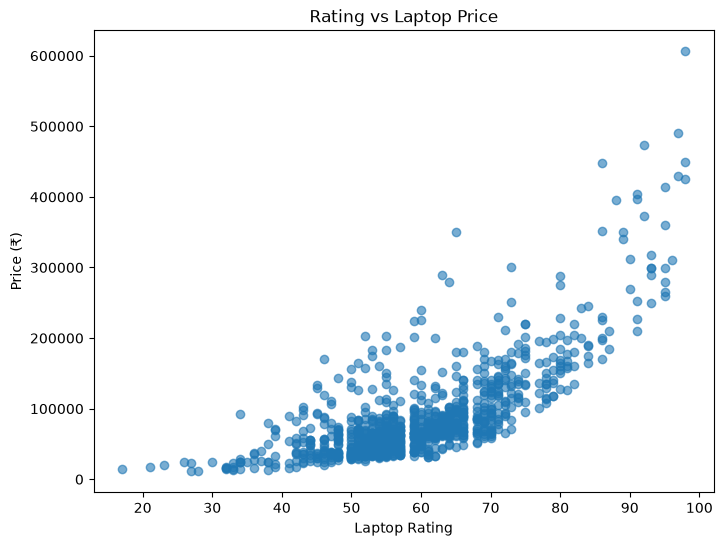

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    df["rating"],
    df["price"],
    alpha=0.6
)

plt.xlabel("Laptop Rating")
plt.ylabel("Price (₹)")
plt.title("Rating vs Laptop Price")

plt.show()

In [34]:
error_analysis = X_test.copy()

error_analysis["Actual Price (₹)"] = y_test.values
error_analysis["Predicted Price (₹)"] = tuned_gradient_predictions

error_analysis["Absolute Error (₹)"] = (
    error_analysis["Actual Price (₹)"] -
    error_analysis["Predicted Price (₹)"]
).abs()

error_analysis["Percentage Error (%)"] = (
    error_analysis["Absolute Error (₹)"] /
    error_analysis["Actual Price (₹)"]
) * 100

error_analysis = error_analysis.sort_values(
    "Absolute Error (₹)",
    ascending=False
)

error_analysis.head(10)

,model,rating,processor,cores,ram,storage,display,graphics,os,warranty,Actual Price (₹),Predicted Price (₹),Absolute Error (₹),Percentage Error (%)
60,HP ZBook Power G11 A8WM1PT Laptop (Intel Core ...,86.0,Intel Core Ultra 9 Series 1 185H,"16 Cores (6P + 8E + 2LP-E), 22 Threads",32 GB DDR5 RAM,1 TB SSD,"16 inches, 1920 x 1200 pixels",6 GB NVIDIA RTX 1000 Ada,Windows 11 OS,1 Year Warranty,225999.0,336533.009995,110534.009995,48.909070
235,Lenovo Thinkpad P16v 21KX002GUS Laptop (Intel ...,73.0,Intel Core Ultra 9 Series 1 185H,"16 Cores (6P + 8E + 2LP-E), 22 Threads",32 GB RAM,1 TB SSD,"16 inches, 1920 x 1200 pixels",NVIDIA RTX 3000 Ada Generation,Windows 11 OS,1 Year Warranty,299999.0,205180.835214,94818.164786,31.606160
432,Asus ROG Strix G16 G615LP-S5022WS Gaming Lapto...,91.0,Intel Core Ultra 9 275HX,"24 Cores (8P + 16E), 24 Threads",32 GB DDR5 RAM,1 TB SSD,"16 inches, 2560 x 1600 pixels",8 GB NVIDIA GeForce RTX 5070,Windows 11 OS,1 Year Warranty,209990.0,277173.147452,67183.147452,31.993498
591,Dell 16 Alienware X16 R2 Gaming Laptop (Intel ...,80.0,Intel Core Ultra 9 Series 1 185H,"16 Cores (6P + 8E + 2LP-E), 22 Threads",32 GB LPDDR5X RAM,1 TB SSD,"16 inches, 2560 x 1600 pixels",8 GB NVIDIA GEFORCE RTX 4070,Windows 11 OS,1 Year Warranty,288490.0,228199.545181,60290.454819,20.898629
428,Asus ROG Strix G16 G615LM-S5128WS Gaming Lapto...,87.0,Intel Core Ultra 9 275HX,"24 Cores (8P + 16E), 24 Threads",16 GB DDR5 RAM,1 TB SSD,"16 inches, 2560 x 1600 pixels",8 GB NVIDIA GeForce RTX 5060,Windows 11 OS,1 Year Warranty,184990.0,239236.049798,54246.049798,29.323774
824,Microsoft Surface Pro 9 5G,34.0,NaN,NaN,8 GB LPDDR5 RAM,128 GB SSD,"13 inches, 2880 x 1920 pixels, Touch Screen",NaN,Windows 11 OS,1 Year Warranty,91990.0,39969.127334,52020.872666,56.550574
895,Gigabyte G6X 9MG-42IN854SH Gaming Laptop (13th...,69.0,13th Gen Intel Core i7 13650HX,14 Cores (6P + 8E),16 GB DDR5 RAM,1 TB SSD,"16 inches, 1920 x 1200 pixels",6 GB NVIDIA GeForce RTX 4050,Windows 11 OS,2 Year Warranty,170000.0,119128.097550,50871.902450,29.924648
558,MSI Vector 16 HX A2XWHG-227IN Gaming Laptop (I...,91.0,Intel Core Ultra 7 255HX,"20 Cores (8P + 12E), 20 Threads",32 GB DDR5 RAM,1 TB SSD,"16 inches, 2560 x 1600 pixels",12 GB NVIDIA GeForce RTX 5070 Ti,Windows 11 OS,2 Year Warranty,226990.0,264639.371157,37649.371157,16.586357
789,Apple MacBook Pro 14 Laptop (Apple M4 Pro/ 24G...,57.0,Apple M4 Pro,12 Cores (8P + 4E),24 GB RAM,512 GB SSD,"14.2 inches, 3024 x 1964 pixels",16 Core GPU,Mac OS,1 Year Warranty,187990.0,152923.006183,35066.993817,18.653649
530,MSI Raider 18 HX AI A2XWIG-255IN Gaming Laptop...,97.0,14th Gen Intel Core i9 14900HX,"24 Cores (8P + 16E), 32 Threads",64 GB DDR5 RAM,4 TB SSD,"18 inches, 3840 x 2400 pixels",16 GB NVIDIA GeForce RTX 5080,Windows 11 OS,2 Year Warranty,429990.0,395477.482443,34512.517557,8.026354


In [35]:
columns_to_check = [
    "processor",
    "cores",
    "ram",
    "storage",
    "display",
    "graphics"
]

for column_name in columns_to_check:
    print(f"\n{'=' * 70}")
    print(column_name.upper())
    print(df[column_name].dropna().sample(
        min(10, df[column_name].notna().sum()),
        random_state=42
    ).tolist())


PROCESSOR
['7th Gen AMD Ryzen 5 7530U', 'Intel Celeron N4500', '13th Gen Intel Core i3 1315U', '13th Gen Intel Core i7 13620H', 'Intel Core Ultra 7 255H', 'Intel Core Ultra 5 225H', 'Intel Core Ultra 5 225H', 'Qualcomm Snapdragon X Plus X1P-42-100', '7th Gen AMD Ryzen 3 7320U', '13th Gen Intel Core i5 1334U']

CORES
['Octa Core (4P + 4E), 8 Threads', 'Octa Core (2P + 4E + 2LP-E), 10 Threads', 'Octa Core (4P + 4E), 12 Threads', 'Octa Core (4P + 4LP-E), 8 Threads', 'Hexa Core, 12 Threads', 'Octa Core, 16 Threads', '10 Cores (2P + 8E), 12 Threads', '16 Cores, 32 Threads', '16 Cores (6P + 8E + 2LP-E), 22 Threads', '12 Cores, 24 Threads']

RAM
['16 GB DDR4 RAM', '16 GB LPDDR5X RAM', '32 GB LPDDR5X RAM', '16 GB LPDDR5X RAM', '16 GB DDR5 RAM', '16 GB DDR4 RAM', '16 GB DDR5 RAM', '32 GB LPDDR5X RAM', '16 GB LPDDR5X RAM', '32 GB LPDDR5X RAM']

STORAGE
['512 GB SSD', '512 GB SSD', '512 GB SSD', '1 TB SSD', '1 TB SSD', '512 GB SSD', '512 GB SSD', '512 GB SSD', '512 GB SSD', '1 TB SSD']

DISPLAY


In [36]:
from sklearn.base import BaseEstimator, TransformerMixin
import pandas as pd
import numpy as np


class LaptopFeatureEngineer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        # -------------------------------------------------
        # RAM → numeric RAM in GB
        # Example: "32 GB DDR5 RAM" → 32
        # -------------------------------------------------
        X["ram_gb"] = pd.to_numeric(
            X["ram"]
            .astype("string")
            .str.extract(
                r"(\d+(?:\.\d+)?)",
                expand=False
            ),
            errors="coerce"
        )

        # -------------------------------------------------
        # Storage → numeric storage in GB
        # Example: "1 TB SSD" → 1024
        # Example: "512 GB SSD" → 512
        # -------------------------------------------------
        storage_text = X["storage"].astype("string")

        storage_value = pd.to_numeric(
            storage_text.str.extract(
                r"(\d+(?:\.\d+)?)",
                expand=False
            ),
            errors="coerce"
        )

        storage_unit = (
            storage_text
            .str.extract(
                r"\d+(?:\.\d+)?\s*(GB|TB)",
                expand=False
            )
            .fillna("")
            .str.upper()
        )

        X["storage_gb"] = storage_value

        X.loc[storage_unit == "TB", "storage_gb"] = (
            storage_value[storage_unit == "TB"] * 1024
        )

        # -------------------------------------------------
        # Screen size → numeric inches
        # Example: "16 inches, 2560 x 1600 pixels" → 16
        # -------------------------------------------------
        X["display_inches"] = pd.to_numeric(
            X["display"]
            .astype("string")
            .str.extract(
                r"(\d+(?:\.\d+)?)\s*inches",
                expand=False
            ),
            errors="coerce"
        )

        # -------------------------------------------------
        # Resolution width and height
        # Example: "2560 x 1600 pixels" → 2560, 1600
        # -------------------------------------------------
        resolution_values = X["display"].astype("string").str.extract(
            r"(\d+)\s*x\s*(\d+)",
            expand=True
        )

        X["resolution_width"] = pd.to_numeric(
            resolution_values[0],
            errors="coerce"
        )

        X["resolution_height"] = pd.to_numeric(
            resolution_values[1],
            errors="coerce"
        )

        # -------------------------------------------------
        # PPI
        # -------------------------------------------------
        X["ppi"] = (
            np.sqrt(
                X["resolution_width"] ** 2 +
                X["resolution_height"] ** 2
            )
            / X["display_inches"]
        )

        # -------------------------------------------------
        # CPU cores
        # Example:
        # "16 Cores (6P + 8E + 2LP-E), 22 Threads" → 16
        # -------------------------------------------------
        X["cpu_cores"] = pd.to_numeric(
            X["cores"]
            .astype("string")
            .str.extract(
                r"(\d+)\s*Cores?",
                expand=False
            ),
            errors="coerce"
        )

        # -------------------------------------------------
        # CPU threads
        # Example:
        # "... 22 Threads" → 22
        # -------------------------------------------------
        X["cpu_threads"] = pd.to_numeric(
            X["cores"]
            .astype("string")
            .str.extract(
                r"(\d+)\s*Threads?",
                expand=False
            ),
            errors="coerce"
        )

        # -------------------------------------------------
        # Remove raw columns converted into numeric features
        # -------------------------------------------------
        X.drop(
            columns=[
                "model",
                "cores",
                "ram",
                "storage",
                "display"
            ],
            inplace=True
        )

        return X

In [37]:
feature_engineer = LaptopFeatureEngineer()

engineered_training_data = feature_engineer.fit_transform(X_train)

print("Original shape :", X_train.shape)
print("New shape      :", engineered_training_data.shape)

print("\nNew columns:")
print(engineered_training_data.columns.tolist())

print("\nSample engineered data:")
display(engineered_training_data.head())

Original shape : (807, 10)
New shape      : (807, 13)

New columns:
['rating', 'processor', 'graphics', 'os', 'warranty', 'ram_gb', 'storage_gb', 'display_inches', 'resolution_width', 'resolution_height', 'ppi', 'cpu_cores', 'cpu_threads']

Sample engineered data:


,rating,processor,graphics,os,warranty,ram_gb,storage_gb,display_inches,resolution_width,resolution_height,ppi,cpu_cores,cpu_threads
29,55.0,Apple M5,10 Core GPU,Mac OS,1 Year Warranty,24,1024,14.2,3024,1964,253.930343,10,<NA>
280,69.0,AMD Ryzen AI 7 350,8 GB NVIDIA GeForce RTX 5050,Windows 11 OS,1 Year Warranty,24,1024,16.0,1920,1200,141.509717,<NA>,16
507,93.0,Intel Core Ultra 9 275HX,12 GB NVIDIA GeForce RTX 5070Ti,Windows 11 OS,1 Year Warranty,32,1024,16.0,2560,1600,188.679623,24,24
706,57.0,12th Gen Intel Core i5 12450H,Intel Integrated UHD Graphics,Windows 11 OS,1 Year Warranty,16,512,15.6,1920,1080,141.211998,<NA>,12
877,51.0,12th Gen Intel Core i5 1235U,Intel Integrated Graphics,Windows 11 OS,1 Year Warranty,8,512,15.6,1920,1080,141.211998,10,12


In [38]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

engineered_numeric_features = [
    "rating",
    "ram_gb",
    "storage_gb",
    "display_inches",
    "resolution_width",
    "resolution_height",
    "ppi",
    "cpu_cores",
    "cpu_threads"
]

engineered_categorical_features = [
    "processor",
    "graphics",
    "os",
    "warranty"
]

engineered_preprocessor = ColumnTransformer([
    (
        "numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ]),
        engineered_numeric_features
    ),
    (
        "categorical",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=2
            ))
        ]),
        engineered_categorical_features
    )
])

print("New preprocessing pipeline created successfully.")

New preprocessing pipeline created successfully.


In [39]:
engineered_training_features = feature_engineer.fit_transform(X_train)
engineered_testing_features = feature_engineer.transform(X_test)

processed_training_features = engineered_preprocessor.fit_transform(
    engineered_training_features
)

processed_testing_features = engineered_preprocessor.transform(
    engineered_testing_features
)

print("Original training shape :", X_train.shape)
print("Engineered training shape:", engineered_training_features.shape)
print("Processed training shape :", processed_training_features.shape)

print("\nOriginal testing shape  :", X_test.shape)
print("Engineered testing shape:", engineered_testing_features.shape)
print("Processed testing shape :", processed_testing_features.shape)

print("\nProcessed data type:", type(processed_training_features))

Original training shape : (807, 10)
Engineered training shape: (807, 13)
Processed training shape : (807, 190)

Original testing shape  : (202, 10)
Engineered testing shape: (202, 13)
Processed testing shape : (202, 190)

Processed data type: <class 'scipy.sparse._csr.csr_matrix'>


In [40]:
improved_gradient_boosting_pipeline = Pipeline([
    (
        "feature_engineering",
        LaptopFeatureEngineer()
    ),
    (
        "preprocessor",
        engineered_preprocessor
    ),
    (
        "model",
        GradientBoostingRegressor(
            n_estimators=700,
            learning_rate=0.05,
            max_depth=4,
            min_samples_split=5,
            min_samples_leaf=2,
            subsample=0.8,
            random_state=42
        )
    )
])

print("Improved Gradient Boosting pipeline created successfully.")

Improved Gradient Boosting pipeline created successfully.


In [41]:
improved_gradient_boosting_pipeline.fit(
    X_train,
    y_train
)

improved_gradient_predictions = (
    improved_gradient_boosting_pipeline.predict(X_test)
)

print("Improved Gradient Boosting pipeline trained successfully.")
print("Number of predictions:", len(improved_gradient_predictions))

Improved Gradient Boosting pipeline trained successfully.
Number of predictions: 202


In [42]:
improved_mae = mean_absolute_error(
    y_test,
    improved_gradient_predictions
)

improved_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        improved_gradient_predictions
    )
)

improved_r2 = r2_score(
    y_test,
    improved_gradient_predictions
)

print("Improved Gradient Boosting")
print("-------------------------")
print("MAE  (₹):", round(improved_mae, 2))
print("RMSE (₹):", round(improved_rmse, 2))
print("R²       :", round(improved_r2, 4))

print("\nPrevious Tuned Gradient Boosting")
print("--------------------------------")
print("MAE  (₹):", round(tuned_gradient_mae, 2))
print("RMSE (₹):", round(tuned_gradient_rmse, 2))
print("R²       :", round(tuned_gradient_r2, 4))

Improved Gradient Boosting
-------------------------
MAE  (₹): 9776.29
RMSE (₹): 17469.35
R²       : 0.9117

Previous Tuned Gradient Boosting
--------------------------------
MAE  (₹): 10592.59
RMSE (₹): 17814.08
R²       : 0.9082


In [43]:
improved_cv_scores = cross_validate(
    improved_gradient_boosting_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring={
        "r2": "r2",
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error"
    },
    n_jobs=-1
)

print("Improved Gradient Boosting - 5 Fold CV")
print("--------------------------------------")

print(
    "CV R² Mean  :",
    round(improved_cv_scores["test_r2"].mean(), 4)
)

print(
    "CV R² Std   :",
    round(improved_cv_scores["test_r2"].std(), 4)
)

print(
    "CV MAE (₹)  :",
    round(-improved_cv_scores["test_mae"].mean(), 2)
)

print(
    "CV RMSE (₹) :",
    round(-improved_cv_scores["test_rmse"].mean(), 2)
)

Improved Gradient Boosting - 5 Fold CV
--------------------------------------
CV R² Mean  : 0.9068
CV R² Std   : 0.0294
CV MAE (₹)  : 12439.02
CV RMSE (₹) : 20898.21


In [44]:
improved_gb_parameters = {
    "model__n_estimators": [300, 500, 700, 900],
    "model__learning_rate": [0.02, 0.03, 0.05, 0.08],
    "model__max_depth": [2, 3, 4, 5],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__subsample": [0.7, 0.8, 0.9, 1.0]
}

improved_gradient_boosting_search = RandomizedSearchCV(
    estimator=improved_gradient_boosting_pipeline,
    param_distributions=improved_gb_parameters,
    n_iter=30,
    cv=5,
    scoring="r2",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

improved_gradient_boosting_search.fit(
    X_train,
    y_train
)

print("Improved Gradient Boosting tuning completed.")

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Improved Gradient Boosting tuning completed.


In [45]:
print("Best Improved Gradient Boosting Parameters:")
print(improved_gradient_boosting_search.best_params_)

print("\nBest CV R²:")
print(
    round(
        improved_gradient_boosting_search.best_score_,
        4
    )
)

Best Improved Gradient Boosting Parameters:
{'model__subsample': 0.7, 'model__n_estimators': 700, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_depth': 5, 'model__learning_rate': 0.02}

Best CV R²:
0.9105


In [46]:
final_gradient_boosting_pipeline = (
    improved_gradient_boosting_search.best_estimator_
)

final_gradient_predictions = (
    final_gradient_boosting_pipeline.predict(X_test)
)

final_gradient_mae = mean_absolute_error(
    y_test,
    final_gradient_predictions
)

final_gradient_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        final_gradient_predictions
    )
)

final_gradient_r2 = r2_score(
    y_test,
    final_gradient_predictions
)

print("Final Tuned Gradient Boosting")
print("----------------------------")
print("MAE  (₹):", round(final_gradient_mae, 2))
print("RMSE (₹):", round(final_gradient_rmse, 2))
print("R²       :", round(final_gradient_r2, 4))

Final Tuned Gradient Boosting
----------------------------
MAE  (₹): 10271.89
RMSE (₹): 18097.51
R²       : 0.9052


In [47]:
final_candidate_predictions = improved_gradient_predictions

final_prediction_check = pd.DataFrame({
    "Actual Price (₹)": y_test.values,
    "Predicted Price (₹)": final_candidate_predictions
})

final_prediction_check["Absolute Error (₹)"] = (
    final_prediction_check["Actual Price (₹)"] -
    final_prediction_check["Predicted Price (₹)"]
).abs()

final_prediction_check["Percentage Error (%)"] = (
    final_prediction_check["Absolute Error (₹)"] /
    final_prediction_check["Actual Price (₹)"]
) * 100

display(
    final_prediction_check
    .sort_values("Absolute Error (₹)", ascending=False)
    .head(10)
)

,Actual Price (₹),Predicted Price (₹),Absolute Error (₹),Percentage Error (%)
153,299999.0,181755.404089,118243.595911,39.414663
159,225999.0,324790.975316,98791.975316,43.713457
119,288490.0,213329.589589,75160.410411,26.053038
185,209990.0,266503.508140,56513.508140,26.912476
182,184990.0,238339.216895,53349.216895,28.838973
193,226990.0,268969.527599,41979.527599,18.493999
49,170000.0,128252.710997,41747.289003,24.557229
1,107990.0,66644.279809,41345.720191,38.286619
105,194999.0,156663.407322,38335.592678,19.659379
118,164990.0,201979.920314,36989.920314,22.419492


In [48]:
model_brands = (
    df["model"]
    .astype("string")
    .str.split()
    .str[0]
)

print("Number of unique brands:", model_brands.nunique())

print("\nBrand counts:")
print(model_brands.value_counts())

Number of unique brands: 22

Brand counts:
model
Lenovo       234
HP           225
Asus         180
Acer         102
MSI           93
Dell          75
Apple         22
Samsung       17
Microsoft     12
Infinix       10
Alienware      7
Gigabyte       7
Motorola       5
Ultimus        4
Thomson        4
Chuwi          3
Primebook      3
Colorful       2
Walker         1
ASUS           1
‎Lenovo        1
Air            1
Name: count, dtype: int64


In [49]:
model_brand = (
    df["model"]
    .astype("string")
    .str.split()
    .str[0]
    .str.strip()
)

rare_brands = model_brand.value_counts()
rare_brands = rare_brands[rare_brands <= 3].index.tolist()

for brand_name in rare_brands:
    print(f"\n{'=' * 60}")
    print("PREFIX:", brand_name)

    matching_models = df.loc[
        model_brand == brand_name,
        "model"
    ]

    for model_name in matching_models:
        print(model_name)


PREFIX: Chuwi
Chuwi CoreBook X Laptop (AMD Ryzen 5 7430U/ 16GB/ 512GB SSD/ Win11)
Chuwi CoreBook X i3 Laptop (10th Gen Core i3/ 8GB/ 256GB SSD/ Win 11)
Chuwi CoreBook X Laptop (12th Gen Core i5/ 16GB/ 512GB SSD/ Win11)

PREFIX: Primebook
Primebook 2 Pro 2025 Laptop (MediaTek Helio G99/ 8GB/ 128GB UFS / PrimeOS 3.0)
Primebook 2 Max 2025 Laptop (MediaTek Helio G99/ 8GB/ 256GB UFS / PrimeOS 3.0)
Primebook 2 Neo 2025 Laptop (MediaTek Helio G99/ 6GB/ 128GB UFS 2.2/ PrimeOS 3.0

PREFIX: Colorful
Colorful Evol P15 23-HE55D16512A-W-IND Gaming Laptop (12th Gen Core i5/ 16GB/ 512GB SSD/ Win11/ 6GB Graph)
Colorful Evol P15 Gaming Laptop (13th Gen Core i7/ 16GB/ 512GB SSD/ Win11/ 8GB Graph)

PREFIX: Walker
Walker NU15A1 Laptop (Celeron N4020/ 8GB/ 256GB SSD / Win11 Home)

PREFIX: ASUS
ASUS Vivobook S14 Flip 2025 TP3402VAO-LZ612WS  Laptop (13th Gen Core i5/ 16GB/ 512GB SSD/ Win11 Home)

PREFIX: ‎Lenovo
‎Lenovo V15 G2 Laptop (Celeron N4500/ 8GB/ 256GB SSD/ Win11)

PREFIX: Air
Air Falcon Series lapt

In [50]:
model_brand = (
    df["model"]
    .astype("string")
    .str.split()
    .str[0]
    .str.strip()
)

model_brand = model_brand.replace({
    "ASUS": "Asus",
    "LENOVO": "Lenovo"
})

print("Unique brands:", model_brand.nunique())

print("\nNormalized brand counts:")
print(model_brand.value_counts())

Unique brands: 21

Normalized brand counts:
model
Lenovo       234
HP           225
Asus         181
Acer         102
MSI           93
Dell          75
Apple         22
Samsung       17
Microsoft     12
Infinix       10
Alienware      7
Gigabyte       7
Motorola       5
Ultimus        4
Thomson        4
Chuwi          3
Primebook      3
Colorful       2
Walker         1
‎Lenovo        1
Air            1
Name: count, dtype: int64


In [51]:
lenovo_values = (
    df["model"]
    .astype("string")
    .str.split()
    .str[0]
    .str.strip()
)

lenovo_values = lenovo_values[
    lenovo_values.str.lower() == "lenovo"
]

print("Unique Lenovo values:")
for value in lenovo_values.unique():
    print(repr(value))

Unique Lenovo values:
'Lenovo'


In [52]:
from sklearn.base import BaseEstimator, TransformerMixin
import pandas as pd
import numpy as np


class LaptopFeatureEngineer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        # -------------------------------------------------
        # Brand from model name
        # -------------------------------------------------
        X["brand"] = (
    X["model"]
    .astype("string")
    .str.split()
    .str[0]
    .str.replace(r"[^a-zA-Z]", "", regex=True)
    .str.lower()
    .replace({
        "asus": "Asus",
        "lenovo": "Lenovo",
        "hp": "HP",
        "acer": "Acer",
        "msi": "MSI",
        "dell": "Dell",
        "apple": "Apple",
        "samsung": "Samsung",
        "microsoft": "Microsoft",
        "infinix": "Infinix",
        "alienware": "Alienware",
        "gigabyte": "Gigabyte",
        "ultimus": "Ultimus",
        "motorola": "Motorola",
        "thomson": "Thomson",
        "primebook": "Primebook",
        "colorful": "Colorful",
        "walker": "Walker",
        "air": "Air",
        "chuwi": "Chuwi"
    })
)

        # -------------------------------------------------
        # RAM → numeric RAM in GB
        # -------------------------------------------------
        X["ram_gb"] = pd.to_numeric(
            X["ram"]
            .astype("string")
            .str.extract(
                r"(\d+(?:\.\d+)?)",
                expand=False
            ),
            errors="coerce"
        )

        # -------------------------------------------------
        # Storage → numeric storage in GB
        # -------------------------------------------------
        storage_text = X["storage"].astype("string")

        storage_value = pd.to_numeric(
            storage_text.str.extract(
                r"(\d+(?:\.\d+)?)",
                expand=False
            ),
            errors="coerce"
        )

        storage_unit = (
            storage_text
            .str.extract(
                r"\d+(?:\.\d+)?\s*(GB|TB)",
                expand=False
            )
            .fillna("")
            .str.upper()
        )

        X["storage_gb"] = storage_value

        X.loc[storage_unit == "TB", "storage_gb"] = (
            storage_value[storage_unit == "TB"] * 1024
        )

        # -------------------------------------------------
        # Screen size
        # -------------------------------------------------
        X["display_inches"] = pd.to_numeric(
            X["display"]
            .astype("string")
            .str.extract(
                r"(\d+(?:\.\d+)?)\s*inches",
                expand=False
            ),
            errors="coerce"
        )

        # -------------------------------------------------
        # Resolution width and height
        # -------------------------------------------------
        resolution_values = X["display"].astype("string").str.extract(
            r"(\d+)\s*x\s*(\d+)",
            expand=True
        )

        X["resolution_width"] = pd.to_numeric(
            resolution_values[0],
            errors="coerce"
        )

        X["resolution_height"] = pd.to_numeric(
            resolution_values[1],
            errors="coerce"
        )

        # -------------------------------------------------
        # PPI
        # -------------------------------------------------
        X["ppi"] = (
            np.sqrt(
                X["resolution_width"] ** 2 +
                X["resolution_height"] ** 2
            )
            / X["display_inches"]
        )

        # -------------------------------------------------
        # CPU cores
        # -------------------------------------------------
        X["cpu_cores"] = pd.to_numeric(
            X["cores"]
            .astype("string")
            .str.extract(
                r"(\d+)\s*Cores?",
                expand=False
            ),
            errors="coerce"
        )

        # -------------------------------------------------
        # CPU threads
        # -------------------------------------------------
        X["cpu_threads"] = pd.to_numeric(
            X["cores"]
            .astype("string")
            .str.extract(
                r"(\d+)\s*Threads?",
                expand=False
            ),
            errors="coerce"
        )

        # -------------------------------------------------
        # Remove raw columns
        # -------------------------------------------------
        X.drop(
            columns=[
                "model",
                "cores",
                "ram",
                "storage",
                "display"
            ],
            inplace=True
        )

        return X

In [53]:
brand_test_data = LaptopFeatureEngineer().fit_transform(X_train)

print("Shape:", brand_test_data.shape)

print("\nColumns:")
print(brand_test_data.columns.tolist())

print("\nBrand values:")
print(
    brand_test_data["brand"]
    .value_counts()
)

Shape: (807, 14)

Columns:
['rating', 'processor', 'graphics', 'os', 'warranty', 'brand', 'ram_gb', 'storage_gb', 'display_inches', 'resolution_width', 'resolution_height', 'ppi', 'cpu_cores', 'cpu_threads']

Brand values:
brand
Lenovo       186
HP           181
Asus         148
Acer          78
MSI           76
Dell          57
Apple         17
Samsung       14
Microsoft     11
Infinix        9
Alienware      6
Gigabyte       5
Ultimus        4
Motorola       4
Thomson        4
Primebook      2
Colorful       2
Walker         1
Air            1
Chuwi          1
Name: count, dtype: int64


In [54]:
engineered_numeric_features = [
    "rating",
    "ram_gb",
    "storage_gb",
    "display_inches",
    "resolution_width",
    "resolution_height",
    "ppi",
    "cpu_cores",
    "cpu_threads"
]

engineered_categorical_features = [
    "processor",
    "graphics",
    "os",
    "warranty",
    "brand"
]


engineered_preprocessor_with_brand = ColumnTransformer([
    (
        "numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ]),
        engineered_numeric_features
    ),

    (
        "categorical",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=2
            ))
        ]),
        engineered_categorical_features
    )
])

print("Preprocessor with brand created successfully.")

Preprocessor with brand created successfully.


In [55]:
engineered_training_data = LaptopFeatureEngineer().fit_transform(X_train)
engineered_testing_data = LaptopFeatureEngineer().transform(X_test)

processed_training_data = engineered_preprocessor_with_brand.fit_transform(
    engineered_training_data
)

processed_testing_data = engineered_preprocessor_with_brand.transform(
    engineered_testing_data
)

print("Engineered training shape :", engineered_training_data.shape)
print("Processed training shape  :", processed_training_data.shape)

print("\nEngineered testing shape  :", engineered_testing_data.shape)
print("Processed testing shape   :", processed_testing_data.shape)

print("\nProcessed data type:")
print(type(processed_training_data))

Engineered training shape : (807, 14)
Processed training shape  : (807, 208)

Engineered testing shape  : (202, 14)
Processed testing shape   : (202, 208)

Processed data type:
<class 'scipy.sparse._csr.csr_matrix'>


In [56]:
gradient_boosting_with_brand = Pipeline([
    (
        "feature_engineering",
        LaptopFeatureEngineer()
    ),

    (
        "preprocessor",
        engineered_preprocessor_with_brand
    ),

    (
        "model",
        GradientBoostingRegressor(
            n_estimators=700,
            learning_rate=0.05,
            max_depth=4,
            min_samples_split=5,
            min_samples_leaf=2,
            subsample=0.8,
            random_state=42
        )
    )
])

print("Gradient Boosting pipeline with brand created successfully.")

Gradient Boosting pipeline with brand created successfully.


In [57]:
gradient_boosting_with_brand.fit(
    X_train,
    y_train
)

brand_gradient_predictions = (
    gradient_boosting_with_brand.predict(X_test)
)

print("Gradient Boosting with brand trained successfully.")
print(
    "Number of predictions:",
    len(brand_gradient_predictions)
)

Gradient Boosting with brand trained successfully.
Number of predictions: 202


In [58]:
brand_gradient_mae = mean_absolute_error(
    y_test,
    brand_gradient_predictions
)

brand_gradient_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        brand_gradient_predictions
    )
)

brand_gradient_r2 = r2_score(
    y_test,
    brand_gradient_predictions
)

print("Gradient Boosting with Brand")
print("---------------------------")
print("MAE  (₹):", round(brand_gradient_mae, 2))
print("RMSE (₹):", round(brand_gradient_rmse, 2))
print("R²       :", round(brand_gradient_r2, 4))

print("\nPrevious Best Model")
print("------------------")
print("MAE  (₹):", 9776.29)
print("RMSE (₹):", 17469.35)
print("R²       :", 0.9117)

Gradient Boosting with Brand
---------------------------
MAE  (₹): 9302.77
RMSE (₹): 15346.3
R²       : 0.9318

Previous Best Model
------------------
MAE  (₹): 9776.29
RMSE (₹): 17469.35
R²       : 0.9117


In [59]:
brand_cv_scores = cross_validate(
    gradient_boosting_with_brand,
    X_train,
    y_train,
    cv=5,
    scoring={
        "r2": "r2",
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error"
    },
    n_jobs=-1
)

brand_cv_r2_mean = brand_cv_scores["test_r2"].mean()
brand_cv_r2_std = brand_cv_scores["test_r2"].std()

brand_cv_mae = -brand_cv_scores["test_mae"].mean()
brand_cv_rmse = -brand_cv_scores["test_rmse"].mean()

print("Gradient Boosting with Brand - 5 Fold CV")
print("----------------------------------------")

print("CV R² Mean  :", round(brand_cv_r2_mean, 4))
print("CV R² Std   :", round(brand_cv_r2_std, 4))
print("CV MAE (₹)  :", round(brand_cv_mae, 2))
print("CV RMSE (₹) :", round(brand_cv_rmse, 2))

Gradient Boosting with Brand - 5 Fold CV
----------------------------------------
CV R² Mean  : 0.9204
CV R² Std   : 0.0254
CV MAE (₹)  : 11753.9
CV RMSE (₹) : 19348.88


In [60]:
trained_gb_model = (
    gradient_boosting_with_brand
    .named_steps["model"]
)

trained_preprocessor = (
    gradient_boosting_with_brand
    .named_steps["preprocessor"]
)

feature_names = (
    trained_preprocessor
    .get_feature_names_out()
)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": trained_gb_model.feature_importances_
})

feature_importance = (
    feature_importance
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

print("Top 20 Important Features:")
display(feature_importance.head(20))

Top 20 Important Features:


,Feature,Importance
0,numeric__rating,0.543571
1,numeric__ram_gb,0.090386
2,numeric__ppi,0.076294
3,numeric__storage_gb,0.060156
4,numeric__resolution_height,0.044212
5,numeric__cpu_cores,0.028865
6,numeric__cpu_threads,0.024297
7,categorical__graphics_24 GB NVIDIA GeForce RTX...,0.023287
8,categorical__brand_Dell,0.011876
9,numeric__display_inches,0.008584


In [61]:
price_range_results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": brand_gradient_predictions
})

price_range_results["Price Range"] = pd.cut(
    price_range_results["Actual Price"],
    bins=[
        0,
        50000,
        100000,
        150000,
        250000,
        float("inf")
    ],
    labels=[
        "Under ₹50K",
        "₹50K–₹1L",
        "₹1L–₹1.5L",
        "₹1.5L–₹2.5L",
        "Above ₹2.5L"
    ]
)

price_range_results["Absolute Error"] = (
    price_range_results["Actual Price"] -
    price_range_results["Predicted Price"]
).abs()

price_range_results["Percentage Error"] = (
    price_range_results["Absolute Error"] /
    price_range_results["Actual Price"]
) * 100


price_range_summary = (
    price_range_results
    .groupby("Price Range", observed=False)
    .agg(
        Laptop_Count=("Actual Price", "count"),
        MAE=("Absolute Error", "mean"),
        Mean_Percentage_Error=("Percentage Error", "mean")
    )
    .reset_index()
)

price_range_summary["MAE"] = (
    price_range_summary["MAE"].round(2)
)

price_range_summary["Mean_Percentage_Error"] = (
    price_range_summary["Mean_Percentage_Error"].round(2)
)

display(price_range_summary)

,Price Range,Laptop_Count,MAE,Mean_Percentage_Error
0,Under ₹50K,56,4465.11,12.89
1,₹50K–₹1L,102,7145.86,10.01
2,₹1L–₹1.5L,21,13386.94,11.10
3,₹1.5L–₹2.5L,18,22482.41,11.82
4,Above ₹2.5L,5,42885.31,13.60


In [62]:
from feature_engineering import LaptopFeatureEngineer

print("LaptopFeatureEngineer imported successfully.")

LaptopFeatureEngineer imported successfully.


In [63]:
feature_engineer = LaptopFeatureEngineer()

engineered_training_data = feature_engineer.fit_transform(X_train)

print("Original training shape :", X_train.shape)
print("Engineered training shape:", engineered_training_data.shape)

print("\nEngineered columns:")
print(engineered_training_data.columns.tolist())

print("\nBrand distribution:")
print(engineered_training_data["brand"].value_counts())

Original training shape : (807, 10)
Engineered training shape: (807, 14)

Engineered columns:
['rating', 'processor', 'graphics', 'os', 'warranty', 'brand', 'ram_gb', 'storage_gb', 'display_inches', 'resolution_width', 'resolution_height', 'ppi', 'cpu_cores', 'cpu_threads']

Brand distribution:
brand
Lenovo       186
HP           181
Asus         148
Acer          78
MSI           76
Dell          57
Apple         17
Samsung       14
Microsoft     11
Infinix        9
Alienware      6
Gigabyte       5
Ultimus        4
Motorola       4
Thomson        4
Primebook      2
Colorful       2
Walker         1
Air            1
Chuwi          1
Name: count, dtype: int64


In [64]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder


numeric_features = [
    "rating",
    "ram_gb",
    "storage_gb",
    "display_inches",
    "resolution_width",
    "resolution_height",
    "ppi",
    "cpu_cores",
    "cpu_threads"
]

categorical_features = [
    "processor",
    "graphics",
    "os",
    "warranty",
    "brand"
]


final_preprocessor = ColumnTransformer([
    (
        "numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ]),
        numeric_features
    ),

    (
        "categorical",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            (
                "onehot",
                OneHotEncoder(
                    handle_unknown="ignore",
                    min_frequency=2
                )
            )
        ]),
        categorical_features
    )
])

print("Final preprocessor created successfully.")

Final preprocessor created successfully.


In [65]:
engineered_testing_data = feature_engineer.transform(X_test)

processed_training_data = final_preprocessor.fit_transform(
    engineered_training_data
)

processed_testing_data = final_preprocessor.transform(
    engineered_testing_data
)

print("Engineered training shape :", engineered_training_data.shape)
print("Processed training shape  :", processed_training_data.shape)

print("\nEngineered testing shape  :", engineered_testing_data.shape)
print("Processed testing shape   :", processed_testing_data.shape)

print("\nProcessed data type:")
print(type(processed_training_data))

Engineered training shape : (807, 14)
Processed training shape  : (807, 208)

Engineered testing shape  : (202, 14)
Processed testing shape   : (202, 208)

Processed data type:
<class 'scipy.sparse._csr.csr_matrix'>


In [66]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import Pipeline


final_laptop_price_pipeline = Pipeline([
    (
        "feature_engineering",
        LaptopFeatureEngineer()
    ),

    (
        "preprocessor",
        final_preprocessor
    ),

    (
        "model",
        GradientBoostingRegressor(
            n_estimators=700,
            learning_rate=0.05,
            max_depth=4,
            min_samples_split=5,
            min_samples_leaf=2,
            subsample=0.8,
            random_state=42
        )
    )
])

print("Final laptop price pipeline created successfully.")

Final laptop price pipeline created successfully.


In [67]:
final_laptop_price_pipeline.fit(
    X_train,
    y_train
)

print("Final laptop price pipeline trained successfully.")

Final laptop price pipeline trained successfully.


In [68]:
final_test_predictions = final_laptop_price_pipeline.predict(X_test)

final_mae = mean_absolute_error(
    y_test,
    final_test_predictions
)

final_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        final_test_predictions
    )
)

final_r2 = r2_score(
    y_test,
    final_test_predictions
)

print("FINAL GRADIENT BOOSTING MODEL")
print("-----------------------------")
print("MAE  (₹):", round(final_mae, 2))
print("RMSE (₹):", round(final_rmse, 2))
print("R²       :", round(final_r2, 4))

FINAL GRADIENT BOOSTING MODEL
-----------------------------
MAE  (₹): 9302.77
RMSE (₹): 15346.3
R²       : 0.9318


In [69]:
print("FINAL MODEL RESULTS")
print("===================")
print("MAE  (₹):", round(final_mae, 2))
print("RMSE (₹):", round(final_rmse, 2))
print("R²       :", round(final_r2, 4))

FINAL MODEL RESULTS
MAE  (₹): 9302.77
RMSE (₹): 15346.3
R²       : 0.9318


In [70]:
final_cv_results = cross_validate(
    final_laptop_price_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring={
        "r2": "r2",
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error"
    },
    n_jobs=-1
)

final_cv_r2_mean = final_cv_results["test_r2"].mean()
final_cv_r2_std = final_cv_results["test_r2"].std()

final_cv_mae = -final_cv_results["test_mae"].mean()
final_cv_rmse = -final_cv_results["test_rmse"].mean()

print("FINAL PIPELINE - 5 FOLD CROSS VALIDATION")
print("-----------------------------------------")
print("CV R² Mean  :", round(final_cv_r2_mean, 4))
print("CV R² Std   :", round(final_cv_r2_std, 4))
print("CV MAE (₹)  :", round(final_cv_mae, 2))
print("CV RMSE (₹) :", round(final_cv_rmse, 2))

FINAL PIPELINE - 5 FOLD CROSS VALIDATION
-----------------------------------------
CV R² Mean  : 0.9204
CV R² Std   : 0.0254
CV MAE (₹)  : 11753.9
CV RMSE (₹) : 19348.88


In [72]:
final_error_analysis = X_test.copy()

# Add actual and predicted prices
final_error_analysis["Actual Price"] = y_test.values
final_error_analysis["Predicted Price"] = final_test_predictions

# Calculate errors
final_error_analysis["Absolute Error"] = (
    final_error_analysis["Actual Price"]
    - final_error_analysis["Predicted Price"]
).abs()

final_error_analysis["Percentage Error"] = (
    final_error_analysis["Absolute Error"]
    / final_error_analysis["Actual Price"]
) * 100

# Create brand from the original model column
final_error_analysis["brand"] = (
    final_error_analysis["model"]
    .astype("string")
    .str.split()
    .str[0]
    .str.replace(r"[^a-zA-Z]", "", regex=True)
    .str.lower()
    .replace({
        "asus": "Asus",
        "lenovo": "Lenovo",
        "hp": "HP",
        "acer": "Acer",
        "msi": "MSI",
        "dell": "Dell",
        "apple": "Apple",
        "samsung": "Samsung",
        "microsoft": "Microsoft",
        "infinix": "Infinix",
        "alienware": "Alienware",
        "gigabyte": "Gigabyte",
        "ultimus": "Ultimus",
        "motorola": "Motorola",
        "thomson": "Thomson",
        "primebook": "Primebook",
        "colorful": "Colorful",
        "walker": "Walker",
        "air": "Air",
        "chuwi": "Chuwi"
    })
)

# Sort by largest error
final_error_analysis = final_error_analysis.sort_values(
    "Absolute Error",
    ascending=False
)

print("Top 10 Largest Prediction Errors:")

display(
    final_error_analysis[
        [
            "model",
            "brand",
            "Actual Price",
            "Predicted Price",
            "Absolute Error",
            "Percentage Error"
        ]
    ].head(10)
)

Top 10 Largest Prediction Errors:


,model,brand,Actual Price,Predicted Price,Absolute Error,Percentage Error
235,Lenovo Thinkpad P16v 21KX002GUS Laptop (Intel ...,Lenovo,299999.0,186745.872026,113253.127974,37.751168
895,Gigabyte G6X 9MG-42IN854SH Gaming Laptop (13th...,Gigabyte,170000.0,115314.357713,54685.642287,32.168025
60,HP ZBook Power G11 A8WM1PT Laptop (Intel Core ...,HP,225999.0,277782.743408,51783.743408,22.913262
432,Asus ROG Strix G16 G615LP-S5022WS Gaming Lapto...,Asus,209990.0,260219.345739,50229.345739,23.919875
530,MSI Raider 18 HX AI A2XWIG-255IN Gaming Laptop...,MSI,429990.0,387807.473114,42182.526886,9.810118
428,Asus ROG Strix G16 G615LM-S5128WS Gaming Lapto...,Asus,184990.0,223109.222924,38119.222924,20.606099
558,MSI Vector 16 HX A2XWHG-227IN Gaming Laptop (I...,MSI,226990.0,264746.821109,37756.821109,16.633694
591,Dell 16 Alienware X16 R2 Gaming Laptop (Intel ...,Dell,288490.0,251918.299101,36571.700899,12.676939
528,Dell Inspiron 13 AI Laptop (Intel Core Ultra 7...,Dell,100990.0,133888.915439,32898.915439,32.576409
631,Samsung Galaxy Book 5 360 np750qha-lg1in Lapto...,Samsung,107990.0,75201.711211,32788.288789,30.362338


In [73]:
import pickle
import os

model_directory = "model"

os.makedirs(
    model_directory,
    exist_ok=True
)

final_pipeline_path = os.path.join(
    model_directory,
    "indian_laptop_price_pipeline.pkl"
)

with open(final_pipeline_path, "wb") as file:
    pickle.dump(
        final_laptop_price_pipeline,
        file
    )

print("Final pipeline saved successfully.")
print("Saved at:", final_pipeline_path)

Final pipeline saved successfully.
Saved at: model\indian_laptop_price_pipeline.pkl


In [74]:
import pickle

saved_pipeline_path = "model/indian_laptop_price_pipeline.pkl"

with open(saved_pipeline_path, "rb") as file:
    loaded_laptop_price_pipeline = pickle.load(file)

print("Saved pipeline loaded successfully.")
print(type(loaded_laptop_price_pipeline))

Saved pipeline loaded successfully.
<class 'sklearn.pipeline.Pipeline'>


In [75]:
sample_laptop = X_test.iloc[[0]]

actual_price = y_test.iloc[0]

predicted_price = loaded_laptop_price_pipeline.predict(
    sample_laptop
)[0]

print("Sample Laptop:")
display(sample_laptop)

print("\nActual Price   : ₹", round(actual_price, 2))
print("Predicted Price: ₹", round(predicted_price, 2))

prediction_error = abs(
    actual_price - predicted_price
)

print("Absolute Error : ₹", round(prediction_error, 2))

Sample Laptop:


,model,rating,processor,cores,ram,storage,display,graphics,os,warranty
628,Samsung Galaxy Book 5 Pro np940xha-lg3in/ Lapt...,75.0,Intel Core Ultra 7 Series 2 258V,"Octa Core (4P + 4E), 8 Threads",32 GB LPDDR5X RAM,1 TB SSD,"14 inches, 2880 x 1800 pixels, Touch Screen",Intel Arc 140V GPU,Windows 11 OS,1 Year Warranty



Actual Price   : ₹ 171990.0
Predicted Price: ₹ 175225.39
Absolute Error : ₹ 3235.39


In [76]:
final_model_summary = {
    "model": "Gradient Boosting Regressor",
    "test_r2": final_r2,
    "test_mae": final_mae,
    "test_rmse": final_rmse,
    "cv_r2_mean": final_cv_r2_mean,
    "cv_r2_std": final_cv_r2_std,
    "cv_mae": final_cv_mae,
    "cv_rmse": final_cv_rmse,
    "training_samples": len(X_train),
    "testing_samples": len(X_test),
    "engineered_features": 14
}

print("FINAL MODEL SUMMARY")
print("===================")

for metric, value in final_model_summary.items():
    print(f"{metric}: {value}")

FINAL MODEL SUMMARY
model: Gradient Boosting Regressor
test_r2: 0.931836236924709
test_mae: 9302.771991458867
test_rmse: 15346.297008233816
cv_r2_mean: 0.9203546729775194
cv_r2_std: 0.025405656006432766
cv_mae: 11753.89870414669
cv_rmse: 19348.876523759136
training_samples: 807
testing_samples: 202
engineered_features: 14


In [77]:
import sys
import sklearn

print("Python:")
print(sys.executable)

print("\nScikit-learn:")
print(sklearn.__version__)

Python:
C:\Users\karta\miniconda3\python.exe

Scikit-learn:
1.9.0
